In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random

In [3]:
names = open('../names.txt').read().splitlines()

# Creating a lookup from string to index to store counts in the torch array

chars = (
            ['.'] +
            sorted(set(''.join(names)))
            )
s2i = {s:i for i,s in enumerate(chars)}
i2s = {s2i[s]:s for s in s2i}

### Generating n-grams

In [433]:
block_size = 3
X, Y = [], []

for n in names:
    context = [0] * block_size
    # print(n)
    for ch in (n + '.'):
        i = s2i[ch]
        X.append(context)
        Y.append(i)
        # print(''.join(i2s[j] for j in context), '--->', i2s[i])
        context = context[1:] + [i]

X, Y = torch.tensor(X), torch.tensor(Y)

## Creating a lookup-table or creating the embedding vector for each character [Rough Work]

In [5]:
C = torch.randn((27,2)) # Creating a 2-dim vector for each letter 
X_emb = C[X]
X_emb.shape

NameError: name 'X' is not defined

In [5]:
W1 = torch.randn((6,100))
b1 = torch.randn(100)

In [6]:
X_emb @ W1 + b1

RuntimeError: mat1 and mat2 shapes cannot be multiplied (96x2 and 6x100)

In [7]:
X_emb.shape

# inputs = 32, n-grams = 3, embeddings = 2

torch.Size([32, 3, 2])

In [8]:
X_emb[3]

tensor([[0.4831, 0.7419],
        [0.2380, 0.0057],
        [0.2380, 0.0057]])

In [41]:
h = torch.tanh(X_emb.view(-1,6) @ W1 + b1)

In [42]:
W2, b2 = torch.randn((100, 27)), torch.randn(27)

In [43]:
logits = h @ W2 + b2

In [50]:
prob = logits.softmax(1)

In [55]:
loss = -prob[torch.arange(32), Y].log().mean()

In [56]:
loss

tensor(17.4003)

### Final Neural Network

In [4]:
X.shape, Y.shape # Sample Dataset

NameError: name 'X' is not defined

In [556]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator=g, requires_grad=True) # Embeddings; 2-dim vector for each letter
W1 = torch.randn((6,100), generator=g, requires_grad=True) # Layer 1 weights
b1 = torch.randn(100, generator=g, requires_grad=True) # Layer 1 bias
W2 = torch.randn((100,27), generator=g, requires_grad=True) # Layer 2 weights
b2 = torch.randn(27, generator=g, requires_grad=True) # Layer 2 bias
parameters = [C, W1, b1, W2, b2]

In [557]:
print('Total parameters:', sum(p.nelement() for p in parameters))

Total parameters: 3481


In [578]:
# Forward pass

X_emb = C[X]
h = torch.tanh(X_emb.view(-1, 6) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Y)
loss

tensor(2.4835, grad_fn=<NllLossBackward0>)

In [559]:
lre = torch.linspace(-3,0,1000)
lrs = 10**lre
# lrs

In [560]:
lrs[0]

tensor(0.0010)

In [ ]:
## FINDING BEST LEARNING RATE

# Backward pass

# lr = 100

lri = []
lossi = []

for i in range(1000):

    # Mini-batch
    ix = torch.randint(0, X.shape[0], (32,))

    X_emb = C[X[ix]]
    h = torch.tanh(X_emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y[ix])

    for p in parameters:
        p.grad = None

    loss.backward()

    for p in parameters:
        lr = lrs[i]
        p.data -= lr * p.grad

    # Track learning rate and loss
    lri.append(lr.item())
    lossi.append(loss.item())

    print(loss.item())

17.888126373291016
18.062349319458008
19.49456024169922
16.49521827697754
16.342042922973633
19.705228805541992
16.95616912841797
18.16092872619629
16.041318893432617
18.842214584350586
18.35686492919922
16.907594680786133
19.8919620513916
21.00754737854004
23.23002815246582
19.18938636779785
19.180421829223633
15.506720542907715
20.542171478271484
17.94015884399414
20.688568115234375
20.37371826171875
17.805034637451172
19.0029296875
19.653026580810547
17.723039627075195
19.54096794128418
16.90188217163086
18.534936904907227
18.95600128173828
14.7767333984375
20.144329071044922
19.040388107299805
19.701400756835938
19.362646102905273
17.156261444091797
18.564571380615234
17.470096588134766
19.753671646118164
15.800924301147461
17.358917236328125
19.482521057128906
17.377506256103516
17.207584381103516
21.414194107055664
18.197429656982422
19.373579025268555
17.668176651000977
17.89464569091797
20.478940963745117
20.304401397705078
18.034332275390625
16.965084075927734
16.3315544128417

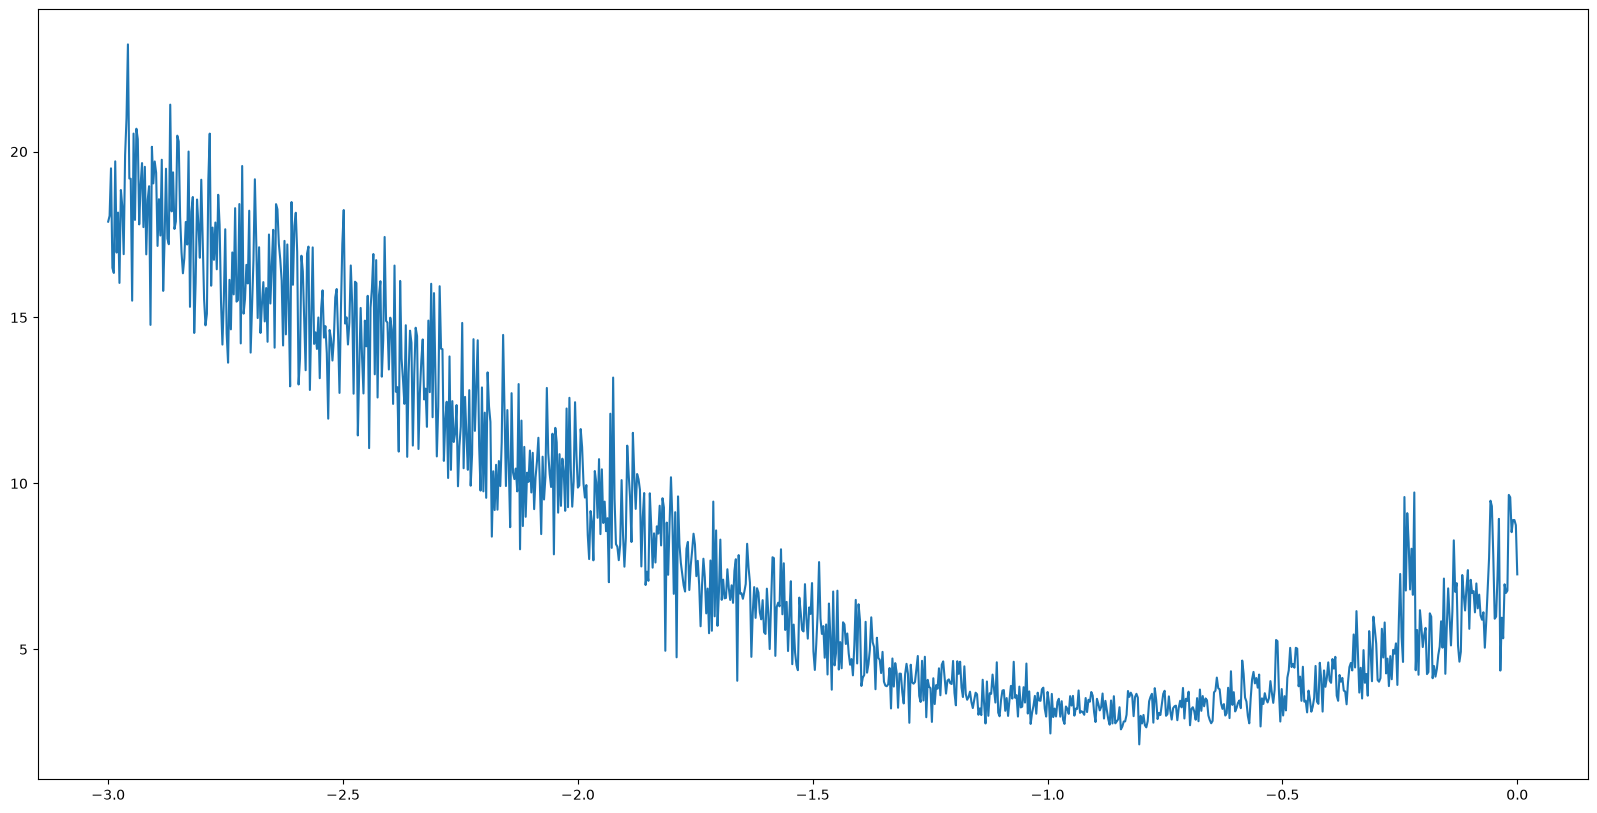

In [563]:
plt.figure(figsize = (20,10))
plt.plot(lre, lossi)

In [570]:
best_learning_rate = lre[torch.tensor(lossi).argmin()].pow(10)

In [581]:
# Backward pass

lr = .01

# lri = []
# lossi = []

for i in range(100000):

    # Mini-batch
    ix = torch.randint(0, X.shape[0], (32,))

    X_emb = C[X[ix]]
    h = torch.tanh(X_emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y[ix])

    for p in parameters:
        p.grad = None

    loss.backward()

    for p in parameters:
        # lr = lrs[i]
        p.data -= lr * p.grad

    # Track learning rate and loss
    # lri.append(lr.item())
    # lossi.append(loss.item())
    if i % 1000 == 0:
        print(f'Epoch {i}: {loss.item()}')
        # print(loss.item())

Epoch 0: 2.094160795211792
Epoch 1000: 2.4032883644104004
Epoch 2000: 2.2755987644195557
Epoch 3000: 2.1519455909729004
Epoch 4000: 2.129988431930542
Epoch 5000: 2.2408621311187744
Epoch 6000: 2.2860965728759766
Epoch 7000: 2.182216167449951
Epoch 8000: 2.0551464557647705
Epoch 9000: 2.357344150543213
Epoch 10000: 2.2384161949157715
Epoch 11000: 2.1866190433502197
Epoch 12000: 2.1902101039886475
Epoch 13000: 2.3463075160980225
Epoch 14000: 2.37644624710083
Epoch 15000: 1.9071108102798462
Epoch 16000: 2.221745252609253
Epoch 17000: 2.2521262168884277
Epoch 18000: 2.1030237674713135
Epoch 19000: 2.14811372756958
Epoch 20000: 2.4023993015289307
Epoch 21000: 2.114245653152466
Epoch 22000: 2.1566927433013916
Epoch 23000: 2.2270374298095703
Epoch 24000: 2.3083338737487793
Epoch 25000: 2.073835849761963
Epoch 26000: 2.390599250793457
Epoch 27000: 2.458129644393921
Epoch 28000: 2.129701852798462
Epoch 29000: 2.145090341567993
Epoch 30000: 2.0547196865081787
Epoch 31000: 2.2784297466278076
Epoc

In [582]:
# Overall loss

X_emb = C[X]
h = torch.tanh(X_emb.view(-1, 6) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Y)
loss


tensor(2.2017, grad_fn=<NllLossBackward0>)

### Use Train-validate-test split

In [8]:
def split(words: list, block_size: int = 3):
    X, y = [], []

    random.seed(42)
    random.shuffle(names)

    for n in names:
        context = [0] * block_size
        # print(n)
        for ch in (n + '.'):
            i = s2i[ch]
            X.append(context)
            y.append(i)
            # print(''.join(i2s[j] for j in context), '--->', i2s[i])
            context = context[1:] + [i]

    N = len(X)
    n1 = int(0.8 * N)
    n2 = int(0.9 * N)

    X_train, y_train = torch.tensor(X[:n1]), torch.tensor(y[:n1])
    X_val, y_val = torch.tensor(X[n1:n2]), torch.tensor(y[n1:n2])
    X_test, y_test = torch.tensor(X[n2:]), torch.tensor(y[n2:])

    return X_train, y_train, X_val, y_val, X_test, y_test

In [49]:
X_train, y_train, X_val, y_val, X_test, y_test = split(words = names, block_size=3)

In [10]:
X_train.shape

torch.Size([182516, 3])

In [11]:
X_test.shape

torch.Size([22815, 3])

In [626]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator=g, requires_grad=True) # Embeddings; 2-dim vector for each letter
W1 = torch.randn((6,100), generator=g, requires_grad=True) # Layer 1 weights
b1 = torch.randn(100, generator=g, requires_grad=True) # Layer 1 bias
W2 = torch.randn((100,27), generator=g, requires_grad=True) # Layer 2 weights
b2 = torch.randn(27, generator=g, requires_grad=True) # Layer 2 bias
parameters = [C, W1, b1, W2, b2]

# Backward pass

lr = best_learning_rate

# lri = []
# lossi = []

for i in range(100000 + 1):

    # Mini-batch
    ix = torch.randint(0, X_train.shape[0], (32,))

    X_emb = C[X_train[ix]]
    h = torch.tanh(X_emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, y_train[ix])

    for p in parameters:
        p.grad = None

    loss.backward()

    for p in parameters:
        # lr = lrs[i]
        p.data -= lr * p.grad

    # Track learning rate and loss
    # lri.append(lr.item())
    # lossi.append(loss.item())
    if i % 1000 == 0:
        print(f'Epoch {i}: {loss.item()}')
        # print(loss.item())

# Overall loss

X_emb_val = C[X_train]
h = torch.tanh(X_emb_val.view(-1, 6) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, y_train)
print(f'Loss on training set: {loss}')

X_emb_val = C[X_val]
h = torch.tanh(X_emb_val.view(-1, 6) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, y_val)
print(f'Loss on validation set: {loss}')

Epoch 0: 16.939346313476562
Epoch 1000: 2.63106632232666
Epoch 2000: 2.3426802158355713
Epoch 3000: 2.5944740772247314
Epoch 4000: 2.3426008224487305
Epoch 5000: 2.3512420654296875
Epoch 6000: 2.849463939666748
Epoch 7000: 2.45344614982605
Epoch 8000: 2.5701375007629395
Epoch 9000: 2.8927416801452637
Epoch 10000: 2.776594400405884
Epoch 11000: 2.556253433227539
Epoch 12000: 2.677386999130249
Epoch 13000: 2.735011577606201
Epoch 14000: 2.3818821907043457
Epoch 15000: 2.9739503860473633
Epoch 16000: 2.6464080810546875
Epoch 17000: 2.6517534255981445
Epoch 18000: 1.9813108444213867
Epoch 19000: 2.298384428024292
Epoch 20000: 2.3269846439361572
Epoch 21000: 2.712744951248169
Epoch 22000: 2.324094772338867
Epoch 23000: 2.1301286220550537
Epoch 24000: 2.280608654022217
Epoch 25000: 2.243252992630005
Epoch 26000: 2.5669102668762207
Epoch 27000: 1.8933662176132202
Epoch 28000: 2.4002068042755127
Epoch 29000: 2.0861129760742188
Epoch 30000: 2.506732702255249
Epoch 31000: 2.6514859199523926
Epoc

### Training and validation loss are functionally equal, so model must be underfitting. Repeat the process with a larger layer 1:

In [121]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 21), generator=g, requires_grad=True) # Embeddings; 2-dim vector for each letter
W1 = torch.randn((63,900), generator=g, requires_grad=True) # Layer 1 weights
b1 = torch.randn(900, generator=g, requires_grad=True) # Layer 1 bias
W2 = torch.randn((900,27), generator=g, requires_grad=True) # Layer 2 weights
b2 = torch.randn(27, generator=g, requires_grad=True) # Layer 2 bias
parameters = [C, W1, b1, W2, b2]

In [122]:
# Backward pass

# lr = 0.01

lri = []
lossi = []

for i in range(1000000):

    # Mini-batch
    ix = torch.randint(0, X_train.shape[0], (30,))

    X_emb = C[X_train[ix]]
    h = torch.tanh(X_emb.view(-1, 63) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, y_train[ix])

    for p in parameters:
        p.grad = None

    loss.backward()

    if i < 100000:
        lr = 0.1
    elif i < 250000:
        lr = 0.01
    elif i < 400000:
        lr = 0.001
    else:
        lr = 0.0001

    for p in parameters:
        # lr = lrs[i]
        p.data -= lr * p.grad

    # Track learning rate and loss
    # lri.append(lr.item() if isinstance(lr, torch.tensor) else)
    lossi.append(loss.log10().item())
    if i % 1000 == 0:
        print(f'Epoch {i}: {loss.item()}')
        # print(loss.item())

# Overall loss

X_emb_val = C[X_train]
h = torch.tanh(X_emb_val.view(-1, 63) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, y_train)
print(f'Loss on training set: {loss}')

X_emb_val = C[X_val]
h = torch.tanh(X_emb_val.view(-1, 63) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, y_val)
print(f'Loss on validation set: {loss}')

Epoch 0: 60.607357025146484
Epoch 1000: 12.84241771697998
Epoch 2000: 10.137192726135254
Epoch 3000: 11.589652061462402
Epoch 4000: 5.63053035736084
Epoch 5000: 6.365010738372803
Epoch 6000: 7.3565263748168945
Epoch 7000: 4.778288841247559
Epoch 8000: 5.304992198944092
Epoch 9000: 4.785227298736572
Epoch 10000: 5.242959976196289
Epoch 11000: 6.361807823181152
Epoch 12000: 3.7413527965545654
Epoch 13000: 3.6004207134246826
Epoch 14000: 5.476179122924805
Epoch 15000: 5.112332344055176
Epoch 16000: 3.2061827182769775
Epoch 17000: 4.171349048614502
Epoch 18000: 3.0656180381774902
Epoch 19000: 4.077772617340088
Epoch 20000: 4.968754768371582
Epoch 21000: 6.569414138793945
Epoch 22000: 5.0418219566345215
Epoch 23000: 5.063536167144775
Epoch 24000: 5.725515842437744
Epoch 25000: 5.553988456726074
Epoch 26000: 3.9696290493011475
Epoch 27000: 4.247865676879883
Epoch 28000: 3.839101552963257
Epoch 29000: 3.2320735454559326
Epoch 30000: 3.275996446609497
Epoch 31000: 4.130715847015381
Epoch 32000

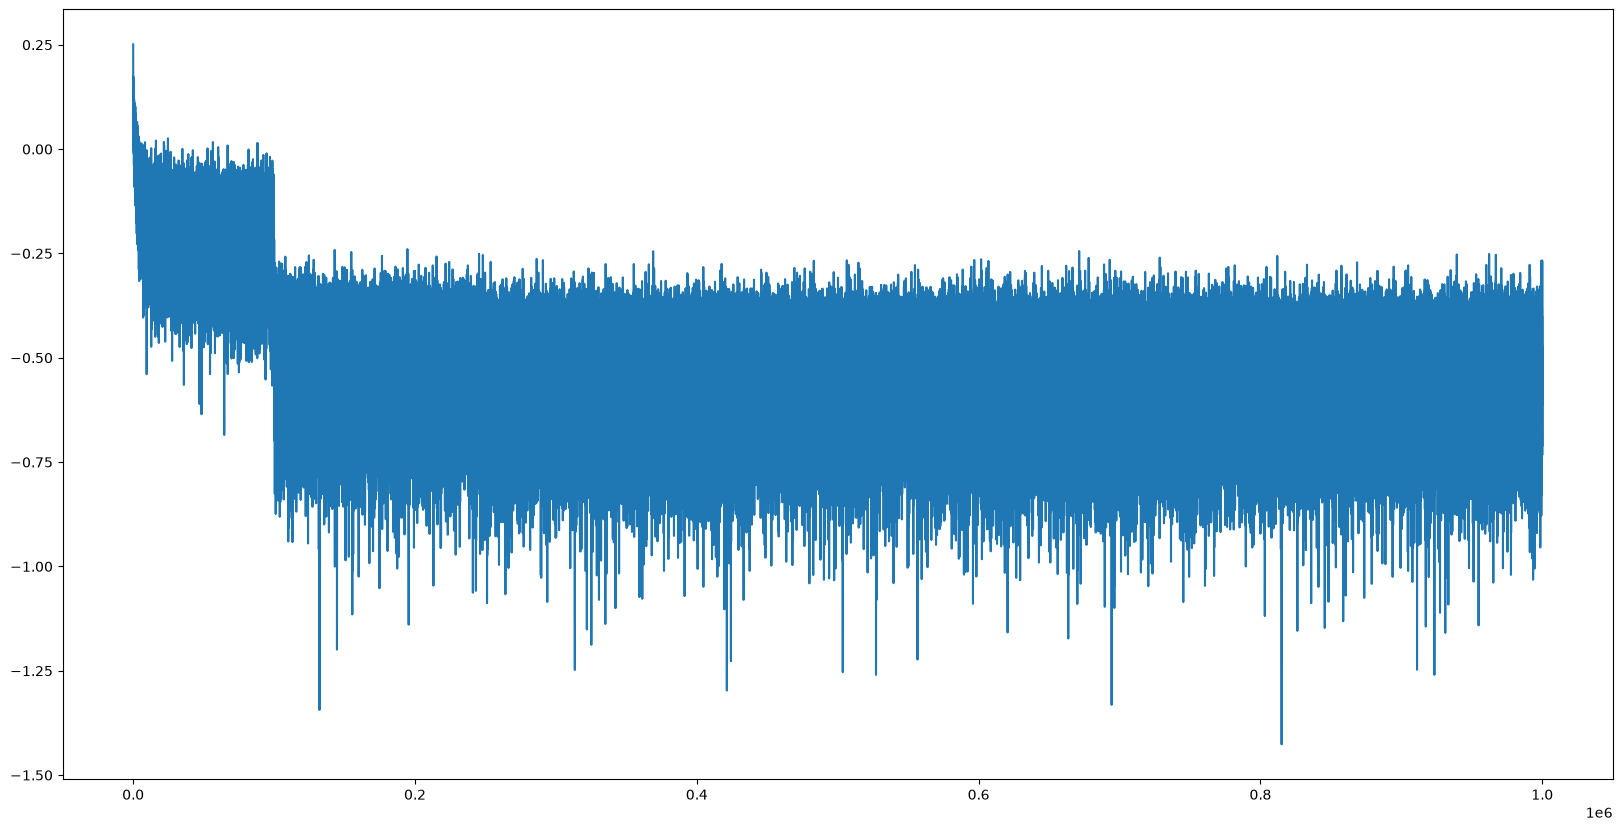

In [123]:
plt.figure(figsize=(20,10))
plt.plot(torch.arange(1, len(lossi)+1), torch.tensor(lossi).log10())

### Visualising embedding vectors

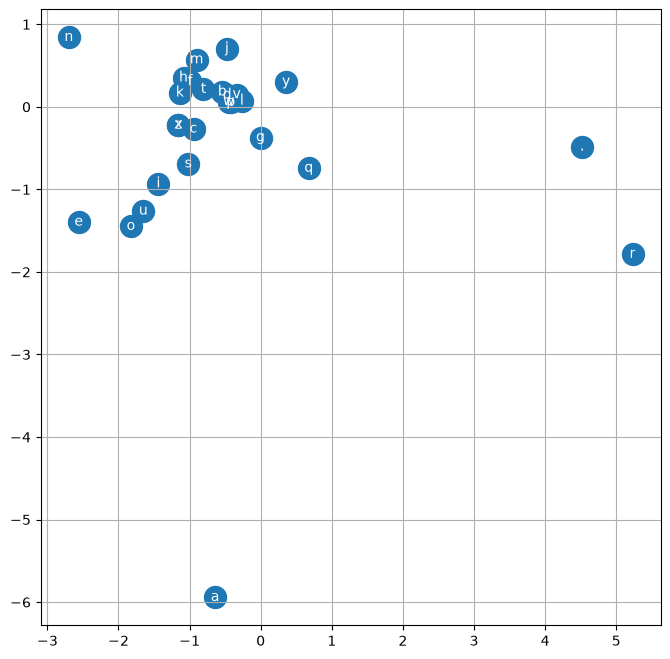

In [124]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s = 250)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), i2s[i], ha='center', va = 'center', color = 'white')
plt.grid('minor')

In [125]:
C.shape

torch.Size([27, 21])

In [126]:
def pca(X, k=2):
    X = X - X.mean(dim=0)                                  # center each column
    U, S, Vh = torch.linalg.svd(X, full_matrices=False)    # Vh rows are the principal directions
    scores = X @ Vh[:k].T                                  # project onto the top k directions
    explained = S**2 / (S**2).sum()                        # variance ratio per component
    return scores, Vh[:k], explained[:k]

scores, components, explained = pca(C, k=2)
print(scores.shape)      # torch.Size([100, 2])
print(components.shape)  # torch.Size([2, 10])
print(explained)         # tensor([0.1508, 0.1423]), varies per run

torch.Size([27, 2])
torch.Size([2, 21])
tensor([0.2998, 0.1934], grad_fn=<SliceBackward0>)


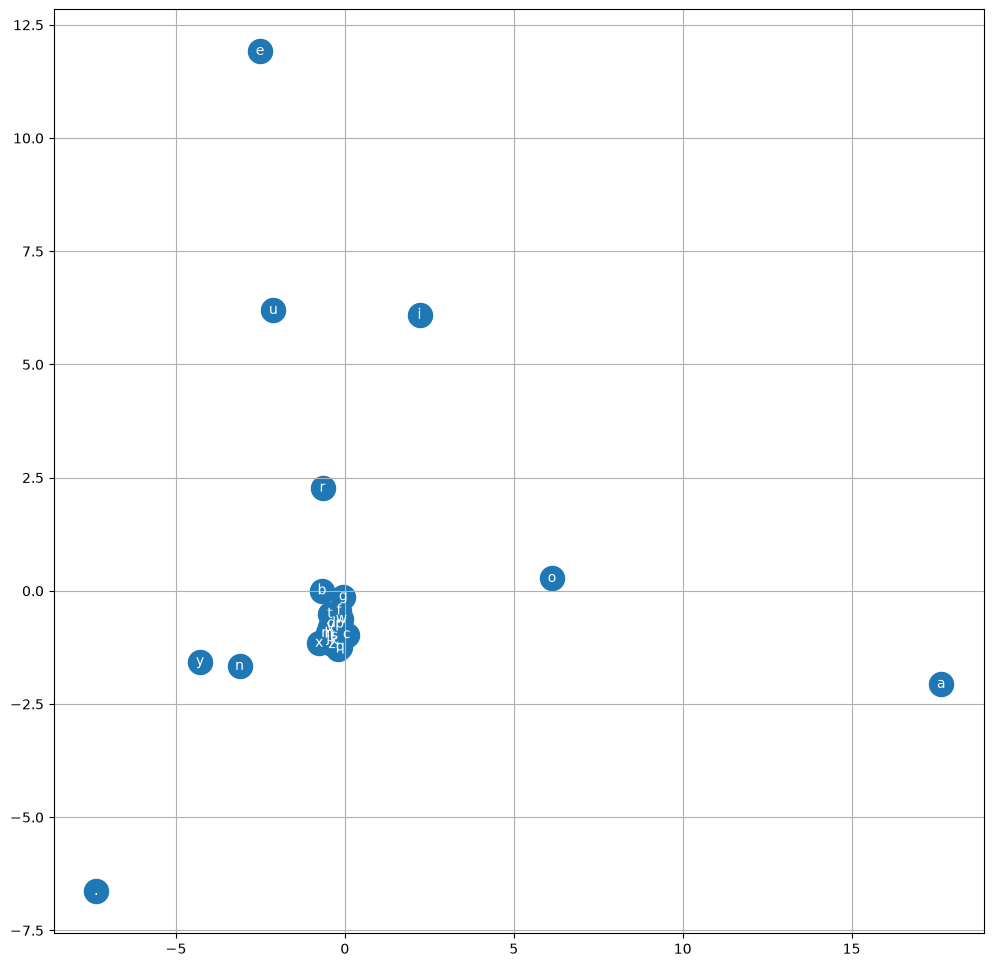

In [138]:
plt.figure(figsize=(12,12))
plt.scatter(scores[:,0].data, scores[:,1].data, s = 300)
for i in range(C.shape[0]):
    plt.text(scores[:,0].tolist()[i], scores[:,1].tolist()[i], i2s[i], ha='center', va = 'center', color = 'white')
plt.grid('minor')

### Generating names

In [1]:
# g = torch.Generator().manual_seed(12345)


for _ in range(10):
    context = [0] * 3
    i = 0
    name = ''
    while True:
        if i > 10000:
            break
        # context = [0] * 3
        emb = C[torch.tensor(context)]
        h = torch.tanh(emb.view(-1, 63) @ W1 + b1)
        l = h @ W2 + b2
        o = l.softmax(1)

        ch_i = torch.multinomial(o,1,replacement=True, generator=g).item()
        if ch_i == 0:
            break
        
        name += i2s[ch_i]
        # print(name)

        context = context[1:] + [ch_i]
        # print(context)

        i += 1

    print(name)
# print(len(name))

NameError: name 'C' is not defined

In [159]:
emb = C[X_test]
h = torch.tanh(emb.view(-1, 63) @ W1 + b1)
l = h @ W2 + b2
p = l.softmax(1)
F.cross_entropy(p,y_test)

tensor(3.1145, grad_fn=<NllLossBackward0>)